In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

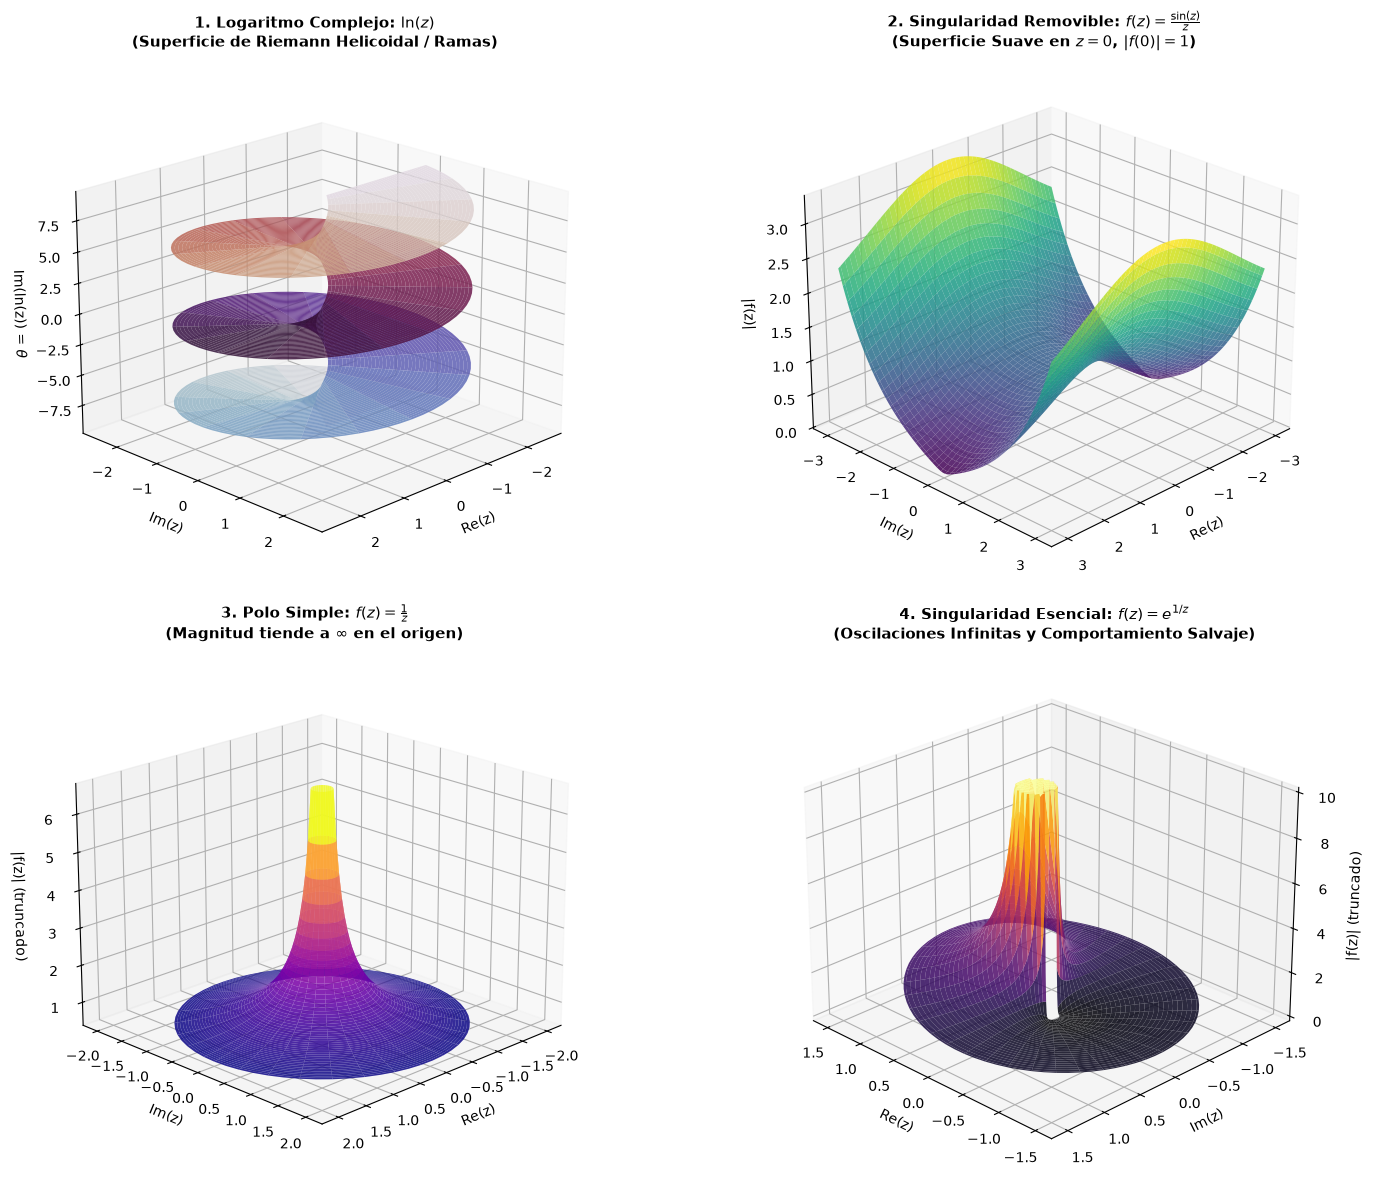

In [3]:
# Configurar figura con 4 paneles 3D
fig = plt.figure(figsize=(16, 12))
#plt.suptitle("Superficies de Riemann en Singularidades de funciones de Variable Compleja", fontsize=16, fontweight='bold')

# -----------------------------------------------------------------------------
# Panel 1: Superficie de Riemann para el Logaritmo Complejo: w = ln(z)
# -----------------------------------------------------------------------------
# La parte imaginaria Im(ln(z)) = Arg(z) + 2*k*pi define las distintas hojas.
ax1 = fig.add_subplot(221, projection='3d')

r = np.linspace(0.1, 2.5, 40)
theta = np.linspace(-3 * np.pi, 3 * np.pi, 200) # 3 vueltas completas (-3pi a 3pi)
R, THETA = np.meshgrid(r, theta)

# Coordenadas en el dominio complejo z = x + i*y
X1 = R * np.cos(THETA)
Y1 = R * np.sin(THETA)
# La superficie helicoidal representa Im(ln(z))
Z1 = THETA  # Transición continua entre hojas

surf1 = ax1.plot_surface(X1, Y1, Z1, cmap=cm.twilight, alpha=0.85, edgecolor='none')
ax1.set_title("1. Logaritmo Complejo: $\ln(z)$\n(Superficie de Riemann Helicoidal / Ramas)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Re(z)")
ax1.set_ylabel("Im(z)")
ax1.set_zlabel("Im(ln(z)) = $\\theta$")
ax1.view_init(elev=20, azim=45)

# -----------------------------------------------------------------------------
# Panel 2: Singularidad Removible: f(z) = sin(z) / z
# -----------------------------------------------------------------------------
# f(0) no está definida formalmente, pero lim_{z->0} f(z) = 1.
# La superficie |f(z)| es perfectamente suave en el origen (se remueve la singularidad).
ax2 = fig.add_subplot(222, projection='3d')

x2 = np.linspace(-3, 3, 100)
y2 = np.linspace(-3, 3, 100)
X2, Y2 = np.meshgrid(x2, y2)
Z_complex2 = X2 + 1j * Y2

# Evitamos división por cero exacta en el origen previendo z = 0
with np.errstate(divide='ignore', invalid='ignore'):
    F2 = np.sin(Z_complex2) / Z_complex2
    F2[Z_complex2 == 0] = 1.0 + 0.0j  # Remoción de la singularidad en z = 0

abs_F2 = np.abs(F2)

surf2 = ax2.plot_surface(X2, Y2, abs_F2, cmap=cm.viridis, alpha=0.85, edgecolor='none')
ax2.set_title("2. Singularidad Removible: $f(z) = \\frac{\\sin(z)}{z}$\n(Superficie Suave en $z=0$, $|f(0)|=1$)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Re(z)")
ax2.set_ylabel("Im(z)")
ax2.set_zlabel("|f(z)|")
ax2.view_init(elev=25, azim=45)

# -----------------------------------------------------------------------------
# Panel 3: Polo de Orden 1: f(z) = 1 / z
# -----------------------------------------------------------------------------
# Cono de magnitud tendiendo a infinito en z = 0 (|f(z)| -> inf).
ax3 = fig.add_subplot(223, projection='3d')

r3 = np.linspace(0.15, 2.0, 50)
theta3 = np.linspace(0, 2 * np.pi, 60)
R3, THETA3 = np.meshgrid(r3, theta3)

X3 = R3 * np.cos(THETA3)
Y3 = R3 * np.sin(THETA3)
Z_complex3 = X3 + 1j * Y3

F3 = 1.0 / Z_complex3
abs_F3 = np.clip(np.abs(F3), 0, 8)  # Truncamos la magnitud para visualización

surf3 = ax3.plot_surface(X3, Y3, abs_F3, cmap=cm.plasma, alpha=0.85, edgecolor='none')
ax3.set_title("3. Polo Simple: $f(z) = \\frac{1}{z}$\n(Magnitud tiende a $\\infty$ en el origen)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Re(z)")
ax3.set_ylabel("Im(z)")
ax3.set_zlabel("|f(z)| (truncado)")
ax3.view_init(elev=20, azim=45)

# -----------------------------------------------------------------------------
# Panel 4: Singularidad Esencial: f(z) = exp(1 / z)
# -----------------------------------------------------------------------------
# Teorema de Casorati-Weierstrass / Picard: Cerca de z = 0, f(z) toma 
# todos los valores complejos infinitas veces (oscilaciones salvajes).
ax4 = fig.add_subplot(224, projection='3d')

r4 = np.linspace(0.08, 1.5, 60)
theta4 = np.linspace(0, 2 * np.pi, 80)
R4, THETA4 = np.meshgrid(r4, theta4)

X4 = R4 * np.cos(THETA4)
Y4 = R4 * np.sin(THETA4)
Z_complex4 = X4 + 1j * Y4

with np.errstate(over='ignore'):
    F4 = np.exp(1.0 / Z_complex4)
    abs_F4 = np.clip(np.abs(F4), 0, 10)  # Truncamos para evitar explosión numérica

surf4 = ax4.plot_surface(X4, Y4, abs_F4, cmap=cm.inferno, alpha=0.85, edgecolor='none')
ax4.set_title("4. Singularidad Esencial: $f(z) = e^{1/z}$\n(Oscilaciones Infinitas y Comportamiento Salvaje)", fontsize=11, fontweight='bold')
ax4.set_xlabel("Re(z)")
ax4.set_ylabel("Im(z)")
ax4.set_zlabel("|f(z)| (truncado)")
ax4.view_init(elev=25, azim=135)

plt.tight_layout()
plt.show()